In [1]:
!pip install -q scikit-learn xgboost shap lime pandas numpy matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


load data


In [ ]:
from google.colab import files

In [ ]:
import pandas as pd
uploaded = files.upload()


Saving malicious_phish.csv to malicious_phish.csv


In [ ]:
df = pd.read_csv('malicious_phish.csv')
print('total url:', len(df))
print(df['type'].value_counts())
df.head()

total url: 651191
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


Filter to phishing + benign, then clean

In [ ]:
start_n = len(df)

df = df[df['type'].str.lower().isin(['phishing', 'benign'])].copy()
df['label'] = df['type'].map(lambda t: 1 if str(t).lower() == 'phishing' else 0)

df['url'] = df['url'].astype(str).str.strip()

df = df[df['url'].str.len() > 3]
malformed = start_n - len(df)

before = len(df)
df = df.drop_duplicates(subset=['url'])
dupes = before - len(df)

df = df[['url', 'label']].reset_index(drop=True)

print('===== CLEANING REPORT =====')
print('Starting rows      :', start_n)
print('After filtering    :', 'phishing + benign only')
print('Malformed removed  :', malformed)
print('Duplicates removed :', dupes)
print('Final rows         :', len(df))
print('Phishing (1)       :', int(df.label.sum()))
print('Benign   (0)       :', int((df.label == 0).sum()))

===== CLEANING REPORT =====
Starting rows      : 651191
After filtering    : phishing + benign only
Malformed removed  : 128980
Duplicates removed : 48
Final rows         : 522163
Phishing (1)       : 94083
Benign   (0)       : 428080


tranco

In [ ]:
# Install and fetch the Tranco list (clean legitimate domains)
!pip install -q tranco

from tranco import Tranco
import pandas as pd

t = Tranco(cache=True, cache_dir='.tranco')
tranco_list = t.list()
top_domains = tranco_list.top(30000)

print('Fetched', len(top_domains), 'Tranco domains')
print('Examples:', top_domains[:5])

# bare domains (no scheme) — scheme is unreliable in this dataset
tranco_df = pd.DataFrame({'url': top_domains, 'label': 0})

df = pd.concat([df, tranco_df], ignore_index=True)
df = df.drop_duplicates(subset=['url']).reset_index(drop=True)

print('\nAfter adding Tranco:')
print('Total:', len(df), '| Phishing:', int(df.label.sum()), '| Benign:', int((df.label==0).sum()))

Fetched 30000 Tranco domains
Examples: ['google.com', 'cloudflare.com', 'facebook.com', 'gstatic.com', 'googleapis.com']

After adding Tranco:
Total: 552156 | Phishing: 94083 | Benign: 458073


Sample for speed (optional, balanced)

In [ ]:
SAMPLE = 120000          # a bit larger to include Tranco variety
if SAMPLE and len(df) > SAMPLE:
    per = SAMPLE // 2
    p = df[df.label == 1].sample(min(per, (df.label==1).sum()), random_state=42)
    l = df[df.label == 0].sample(min(per, (df.label==0).sum()), random_state=42)
    df = pd.concat([p, l]).sample(frac=1, random_state=42).reset_index(drop=True)
print('Using', len(df), 'URLs | Phishing:', int(df.label.sum()), '| Benign:', int((df.label==0).sum()))

Using 120000 URLs | Phishing: 60000 | Benign: 60000


Feature extraction

In [ ]:
import re, math
from urllib.parse import urlparse
from tqdm import tqdm
tqdm.pandas()

def entropy(s):
    if not s: return 0.0
    fr = {}
    for c in s: fr[c] = fr.get(c, 0) + 1
    n = len(s)
    return -sum((v/n)*math.log2(v/n) for v in fr.values())

SUSP = ['login','secure','account','update','verify','banking','confirm','password',
        'signin','paypal','ebay','amazon','support','service','free','lucky','bonus','click','webscr']
BRANDS = ['paypal','amazon','ebay','apple','microsoft','netflix','facebook',
          'google','bank','instagram','whatsapp','outlook','office365']
SHORT = ['bit.ly','tinyurl','goo.gl','t.co','ow.ly','is.gd','cutt.ly']
CT = ['.com','.org','.net','.edu','.gov']
ST = ['.xyz','.tk','.ml','.ga','.cf','.gq','.top','.click','.link','.online','.site','.work']

def _normalise(url):
    u = str(url).strip().lower()
    u = re.sub(r'^https?://', '', u)
    u = re.sub(r'^www\.', '', u)
    return u

def feats(url):
    norm = _normalise(url)
    parts = norm.split('/', 1)
    d = parts[0]
    pa = '/' + parts[1] if len(parts) > 1 else ''
    u = norm
    f = {}
    f['url_length']=len(u); f['domain_length']=len(d); f['path_length']=len(pa)
    f['num_dots']=u.count('.'); f['num_hyphens']=u.count('-'); f['num_underscores']=u.count('_')
    f['num_slashes']=u.count('/'); f['num_question_marks']=u.count('?'); f['num_equal_signs']=u.count('=')
    f['num_at_signs']=u.count('@'); f['num_ampersands']=u.count('&'); f['num_percent']=u.count('%')
    f['num_digits']=sum(c.isdigit() for c in u); f['num_subdomains']=max(0, d.count('.')-1)
    f['url_entropy']=round(entropy(u),4); f['domain_entropy']=round(entropy(d),4)
    f['digit_ratio']=round(f['num_digits']/max(len(u),1),4)
    host = d.split(':')[0]
    f['has_ip']=int(bool(re.match(r'^\d{1,3}(\.\d{1,3}){3}$', host)))
    f['has_port']=int(':' in d)
    f['is_shortened']=int(any(s in d for s in SHORT))
    f['has_suspicious_word']=int(any(w in u for w in SUSP))
    f['has_double_slash']=int('//' in pa); f['has_prefix_suffix']=int('-' in d)
    f['path_depth']=len([x for x in pa.split('/') if x])
    tld = '.'+d.split('.')[-1] if '.' in d else ''
    f['is_common_tld']=int(tld in CT); f['is_suspicious_tld']=int(tld in ST)
    f['brand_impersonation']=int(any(b in u and not d.endswith(b+'.com') for b in BRANDS))
    f['num_suspicious_words']=sum(1 for w in SUSP if w in u)
    f['digits_in_domain']=sum(c.isdigit() for c in d)
    f['long_domain']=int(len(d) > 30)
    return f

fx = df['url'].progress_apply(lambda u: pd.Series(feats(u)))
data = pd.concat([fx, df['label']], axis=1)
print('Feature matrix:', data.shape)
data.head()

100%|██████████| 120000/120000 [00:34<00:00, 3436.10it/s]

Feature matrix: (120000, 31)


,url_length,domain_length,path_length,num_dots,num_hyphens,num_underscores,num_slashes,num_question_marks,num_equal_signs,num_at_signs,...,has_double_slash,has_prefix_suffix,path_depth,is_common_tld,is_suspicious_tld,brand_impersonation,num_suspicious_words,digits_in_domain,long_domain,label
0,10.0,10.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,20.0,19.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0
2,31.0,30.0,1.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1
3,38.0,14.0,24.0,3.0,3.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,58.0,22.0,36.0,2.0,0.0,1.0,2.0,0.0,0.0,0.0,...,0.0,0.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,1


Split 80/20 + scoring helper

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

cols = [c for c in data.columns if c != 'label']
X, y = data[cols], data['label']

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20,
                                      random_state=42, stratify=y)
print('Train:', len(Xtr), ' Test:', len(Xte), '(80/20 split)')

def score(name, model):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    print(f'\n===== {name} =====')
    print('Accuracy :', round(accuracy_score(yte, pred), 4))
    print('Precision:', round(precision_score(yte, pred), 4))
    print('Recall   :', round(recall_score(yte, pred), 4))
    print('F1       :', round(f1_score(yte, pred), 4))
    print('ROC-AUC  :', round(roc_auc_score(yte, proba), 4))
    return {'Model':name,'Accuracy':round(accuracy_score(yte,pred),4),
            'Precision':round(precision_score(yte,pred),4),
            'Recall':round(recall_score(yte,pred),4),
            'F1':round(f1_score(yte,pred),4),
            'ROC-AUC':round(roc_auc_score(yte,proba),4)}

all_results = []

Train: 96000  Test: 24000 (80/20 split)


Logistic Regression (baseline)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr = Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=1000))])
lr.fit(Xtr, ytr)
all_results.append(score('Logistic Regression', lr))


===== Logistic Regression =====
Accuracy : 0.6966
Precision: 0.6572
Recall   : 0.8221
F1       : 0.7304
ROC-AUC  : 0.7484


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(Xtr, ytr)
all_results.append(score('Random Forest', rf))


===== Random Forest =====
Accuracy : 0.8262
Precision: 0.8042
Recall   : 0.8623
F1       : 0.8323
ROC-AUC  : 0.9088


Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, max_depth=5,
                                learning_rate=0.1, random_state=42)
gb.fit(Xtr, ytr)
all_results.append(score('Gradient Boosting', gb))


===== Gradient Boosting =====
Accuracy : 0.8031
Precision: 0.7888
Recall   : 0.8279
F1       : 0.8079
ROC-AUC  : 0.8886


XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=150, max_depth=7, learning_rate=0.1,
                    random_state=42, eval_metric='logloss', verbosity=0)
xgb.fit(Xtr, ytr)
all_results.append(score('XGBoost', xgb))


===== XGBoost =====
Accuracy : 0.8243
Precision: 0.8075
Recall   : 0.8515
F1       : 0.8289
ROC-AUC  : 0.9076


Comparison table + best model

In [ ]:
rdf = pd.DataFrame(all_results).set_index('Model')
print('===== MODEL COMPARISON =====')
print(rdf.to_string())

best_name = rdf['F1'].idxmax()
best_model = {'Logistic Regression':lr, 'Random Forest':rf,
              'Gradient Boosting':gb, 'XGBoost':xgb}[best_name]
print('\nBest model:', best_name)
rdf

===== MODEL COMPARISON =====
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.6966     0.6572  0.8221  0.7304   0.7484
Random Forest          0.8262     0.8042  0.8623  0.8323   0.9088
Gradient Boosting      0.8031     0.7888  0.8279  0.8079   0.8886
XGBoost                0.8243     0.8075  0.8515  0.8289   0.9076

Best model: Random Forest


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.6966,0.6572,0.8221,0.7304,0.7484
Random Forest,0.8262,0.8042,0.8623,0.8323,0.9088
Gradient Boosting,0.8031,0.7888,0.8279,0.8079,0.8886
XGBoost,0.8243,0.8075,0.8515,0.8289,0.9076


Confusion matrix

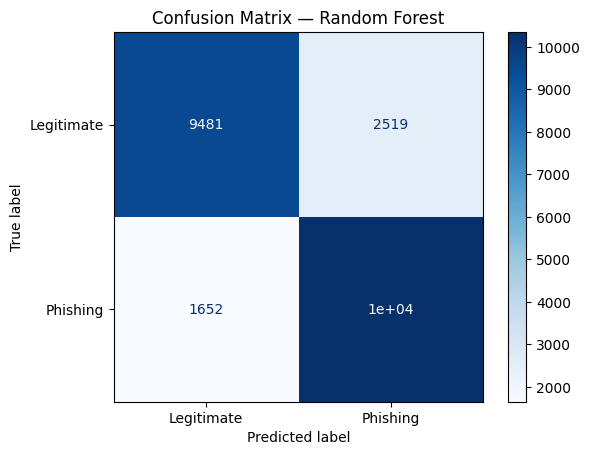

              precision    recall  f1-score   support

  Legitimate       0.85      0.79      0.82     12000
    Phishing       0.80      0.86      0.83     12000

    accuracy                           0.83     24000
   macro avg       0.83      0.83      0.83     24000
weighted avg       0.83      0.83      0.83     24000



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

pred = best_model.predict(Xte)
ConfusionMatrixDisplay(confusion_matrix(yte, pred),
    display_labels=['Legitimate','Phishing']).plot(cmap='Blues')
plt.title('Confusion Matrix — ' + best_name); plt.show()
print(classification_report(yte, pred, target_names=['Legitimate','Phishing']))

SHAP (XAI global)

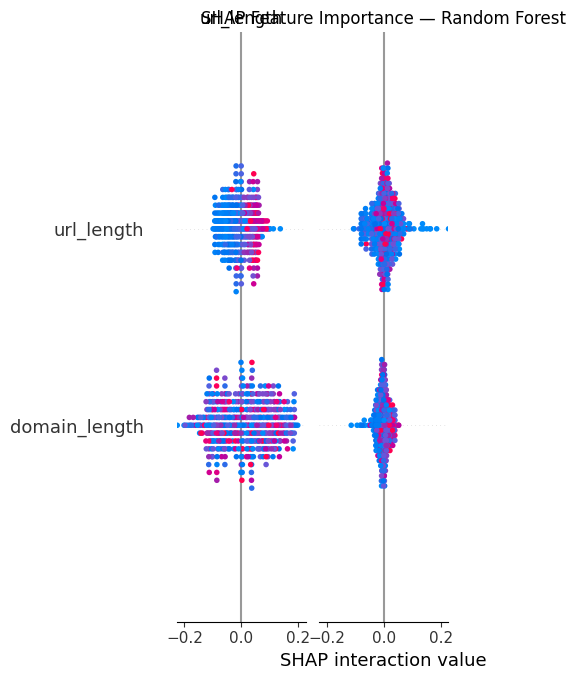

In [ ]:
import shap
if best_name in ('Random Forest','Gradient Boosting','XGBoost'):
    s = Xte.sample(min(500, len(Xte)), random_state=42)
    ex = shap.TreeExplainer(best_model)
    sv = ex.shap_values(s, check_additivity=False)   # skips a slow check
    sv = sv[1] if isinstance(sv, list) else sv
    shap.summary_plot(sv, s, feature_names=cols, plot_type='bar', show=False)
    plt.title('SHAP Feature Importance — ' + best_name); plt.show()

LIME (XAI local)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


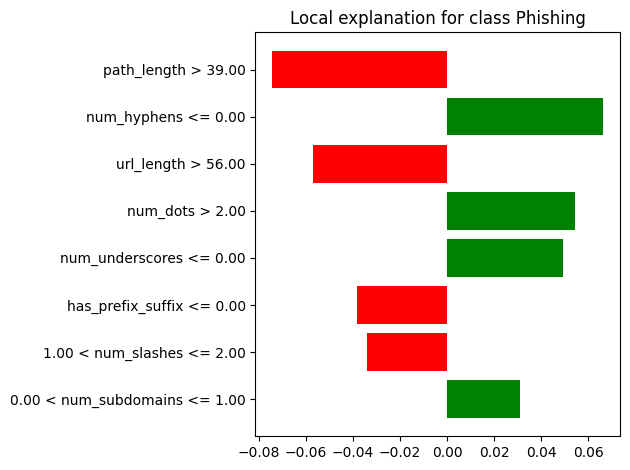

True label: Phishing


In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_ex = LimeTabularExplainer(Xtr.values, feature_names=cols,
                               class_names=['Legitimate','Phishing'],
                               mode='classification')
i = 0   # change to explain a different test URL
exp = lime_ex.explain_instance(Xte.values[i], best_model.predict_proba, num_features=8)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()
print('True label:', 'Phishing' if yte.values[i]==1 else 'Legitimate')

Adaptive learning (RQ1)

In [ ]:
n = len(X); b = n // 3
b1 = (X.iloc[:b], y.iloc[:b])
rf_a = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_a.fit(*b1)

rows = []
for i, sl in enumerate([slice(b, 2*b), slice(2*b, n)], start=2):
    bx, by = X.iloc[sl], y.iloc[sl]
    if by.nunique() < 2: continue
    f_before = round(f1_score(by, rf_a.predict(bx)), 4)
    rf_a.fit(pd.concat([b1[0], bx]), pd.concat([b1[1], by]))
    f_after = round(f1_score(by, rf_a.predict(bx)), 4)
    rows.append({'Batch':f'Batch {i}','F1 static':f_before,
                 'F1 retrained':f_after,'Change':round(f_after-f_before,4)})

print('===== ADAPTIVE LEARNING (RQ1) =====')
print(pd.DataFrame(rows).to_string(index=False))

===== ADAPTIVE LEARNING (RQ1) =====
  Batch  F1 static  F1 retrained  Change
Batch 2     0.8297        0.8793  0.0496
Batch 3     0.8328        0.8797  0.0469


Save & download

In [ ]:
import pickle
from google.colab import files

with open('best_model.pkl', 'wb') as f:
    pickle.dump({'model': best_model, 'model_name': best_name, 'feature_cols': cols}, f)

out = data.copy(); out.insert(0, 'url', df['url'].values)
out.to_csv('dataset.csv', index=False)

files.download('best_model.pkl')
files.download('dataset.csv')
print('Downloaded best_model.pkl and dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded best_model.pkl and dataset.csv


In [ ]:
for d in ['google.com','facebook.com','wikipedia.org']:
    print(d, ':', d in df['url'].values or ('https://www.'+d) in df['url'].values)

google.com : False
facebook.com : False
wikipedia.org : True
